In [2]:
# Librerías necesarias
!pip install transformers datasets torch pandas matplotlib seaborn


In [3]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, BitsAndBytesConfig
import torch


In [4]:
# LLM BERT EN REDES 5G
!git clone https://github.com/freddyAdjh/Federated-security.git
%cd Federated-security


Cloning into 'Federated-security'...
remote: Enumerating objects: 14, done.
remote: Counting objects: 100% (14/14), done.
remote: Compressing objects: 100% (13/13), done.
remote: Total 14 (delta 3), reused 7 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (14/14), 6.98 KiB | 6.98 MiB/s, done.
Resolving deltas: 100% (3/3), done.
/content/Federated-security


In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
from pathlib import Path

carpeta = Path("/content/drive/MyDrive/Colab Notebooks/MODELOS LLM")

train_path = carpeta / "UNSW_NB15_training-set.csv"
test_path = carpeta / "UNSW_NB15_testing-set.csv"

print("Entrenamiento:", train_path.exists())
print("Prueba:", test_path.exists())

Entrenamiento: True
Prueba: True


In [7]:
print(train_path.exists())
print(test_path.exists())

True
True


In [8]:
import pandas as pd

train_nb15 = pd.read_csv(train_path)
test_nb15 = pd.read_csv(test_path)

# Verificar Registros
train_nb15['label'].value_counts()
train_nb15['attack_cat'].value_counts()


,count
attack_cat,
Normal,56000
Generic,40000
Exploits,33393
Fuzzers,18184
DoS,12264
Reconnaissance,10491
Analysis,2000
Backdoor,1746
Shellcode,1133


In [ ]:
# ==== Semillas para reproducibilidad ====
import os, random, numpy as np, torch
from transformers import set_seed

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# para que cuDNN no cambie heurísticas entre ejecuciones
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# utilidad de transformers (afecta generadores internos)
set_seed(SEED)
# =======================================

print("✅ Datos cargados")
print("Entrenamiento:", train_nb15.shape)
print("Pruebas:", test_nb15.shape)

train_nb15.head()

✅ Datos cargados
Entrenamiento: (175341, 45)
Pruebas: (82332, 45)


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


In [ ]:
# === Usar dataset completo (sin reducción de muestras) ===
train_df_full = train_nb15.copy()
test_df_full  = test_nb15.copy()

# Construcción de la secuencia textual
train_df_full['text'] = train_df_full['proto'] + " " + train_df_full['service'] + " " + train_df_full['state']
test_df_full['text']  = test_df_full['proto']  + " " + test_df_full['service']  + " " + test_df_full['state']

In [ ]:
# === Reducir entrenamiento con muestra estratificada y balanceada por 'label' ===

def balanced_by_label(df, label_col, max_total, random_state):
    vc = df[label_col].value_counts()
    clases = vc.index.tolist()
    per_class = max_total // len(clases)

    partes = []
    for c in clases:
        n = min(per_class, int(vc[c]))
        partes.append(df[df[label_col] == c].sample(n=n, replace=False, random_state=random_state))

    out = pd.concat(partes, axis=0).sample(frac=1.0, random_state=random_state).reset_index(drop=True)
    return out

# Ajusta max_total al tamaño que quieras usar en entrenamiento
train_df_full = balanced_by_label(train_df_full, label_col='label', max_total=15_000, random_state=SEED)



In [ ]:
from transformers import BertTokenizer, BertForSequenceClassification

tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
model = BertForSequenceClassification.from_pretrained('bert-base-uncased', num_labels=2)

train_encodings = tokenizer(list(train_df_full['text']), truncation=True, padding='max_length', max_length=16)
test_encodings = tokenizer(list(test_df_full['text']), truncation=True, padding='max_length', max_length=16)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
from torch.utils.data import Dataset, DataLoader
import torch

class TextClsDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, idx):
        item = {k: torch.tensor(v[idx], dtype=torch.long) for k, v in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

train_dataset_full = TextClsDataset(train_encodings, list(train_df_full['label']))
test_dataset_full  = TextClsDataset(test_encodings,  list(test_df_full['label']))

g = torch.Generator(); g.manual_seed(SEED)  # opcional, para shuffle reproducible
train_loader = DataLoader(train_dataset_full, batch_size=16, shuffle=True, generator=g, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset_full,  batch_size=16, shuffle=False, num_workers=2, pin_memory=True)

In [ ]:
from torch.utils.data import DataLoader
from torch.optim import AdamW
import torch
import torch.nn.utils as nn_utils

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

optimizer = AdamW(model.parameters(), lr=2e-5)
MAX_GRAD_NORM = 1.0

model.train()
for epoch in range(1):
    running_loss = 0.0
    for batch in train_loader:
        optimizer.zero_grad()
        outputs = model(
            batch['input_ids'].to(device),
            attention_mask=batch['attention_mask'].to(device),
            labels=batch['labels'].to(device)
        )
        loss = outputs.loss
        loss.backward()

        # ✅ Gradient clipping (nuevo)
        nn_utils.clip_grad_norm_(model.parameters(), max_norm=MAX_GRAD_NORM)

        optimizer.step()
        running_loss += loss.item()
    print(f"✅ Época {epoch+1} completada – Loss: {loss.item():.4f}")

✅ Época 1 completada – Loss: 0.2873


              precision    recall  f1-score   support

      Normal       0.72      0.87      0.79     37000
      Ataque       0.87      0.73      0.79     45332

    accuracy                           0.79     82332
   macro avg       0.80      0.80      0.79     82332
weighted avg       0.81      0.79      0.79     82332



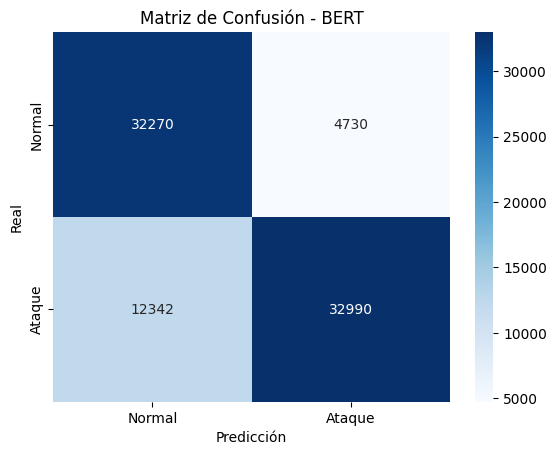

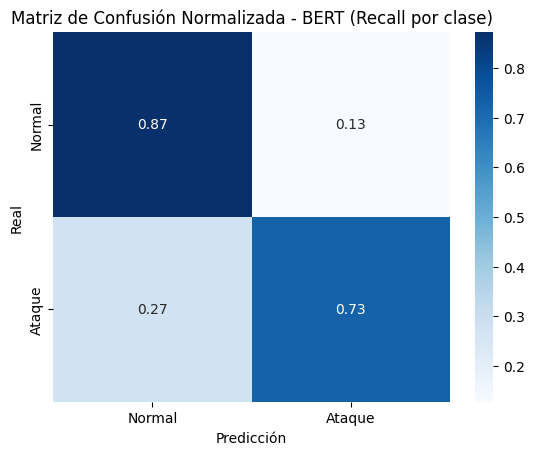

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import torch
import numpy as np

model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for batch in test_loader:
        outputs = model(
            batch['input_ids'].to(device),
            attention_mask=batch['attention_mask'].to(device)
        )
        preds = torch.argmax(outputs.logits, dim=-1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(batch['labels'].cpu().numpy())

print(classification_report(all_labels, all_preds,
                            target_names=['Normal','Ataque'],
                            digits=2, zero_division=0))

# Matriz de confusión (cuentas absolutas)
cm = confusion_matrix(all_labels, all_preds, labels=[0,1])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal','Ataque'],
            yticklabels=['Normal','Ataque'])
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.title('Matriz de Confusión - BERT')
plt.show()

# (Opcional) Matriz normalizada por verdaderos (recall por clase)
cm_norm = cm.astype(np.float64) / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=['Normal','Ataque'],
            yticklabels=['Normal','Ataque'])
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.title('Matriz de Confusión Normalizada - BERT (Recall por clase)')
plt.show()

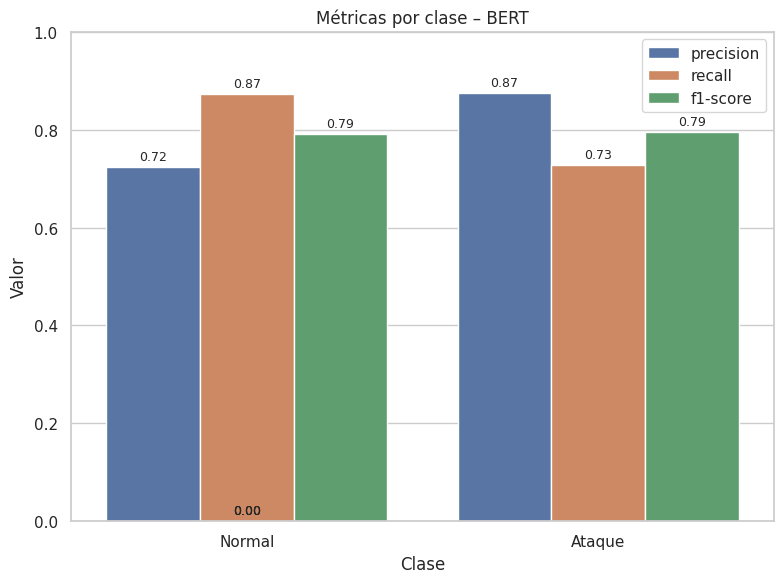

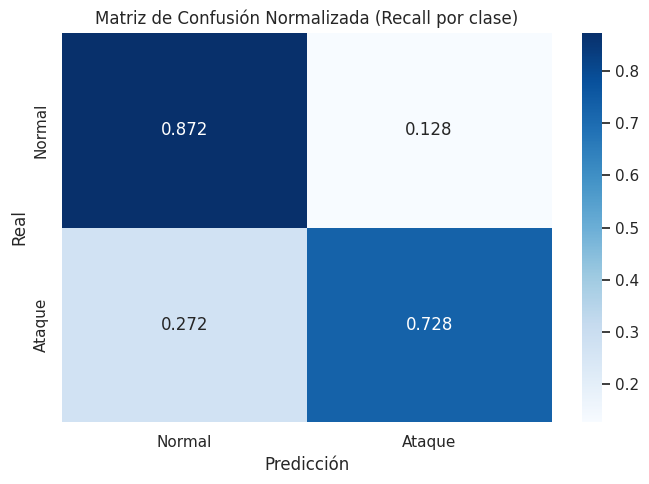

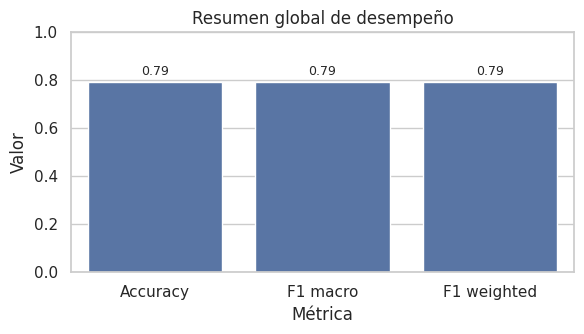

In [ ]:
# Requiere: all_labels, all_preds (del bloque anterior)
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

# ===== 1) Barras por clase: precision / recall / F1 (valores en decimales) =====
rep = classification_report(
    all_labels, all_preds,
    target_names=['Normal','Ataque'],
    output_dict=True, zero_division=0
)
df_metrics = pd.DataFrame(rep).T  # filas: Normal, Ataque, accuracy, macro avg, weighted avg
classes = ['Normal','Ataque']
plot_df = df_metrics.loc[classes, ['precision','recall','f1-score']].reset_index().rename(columns={'index':'Clase'})
plot_df = plot_df.melt(id_vars='Clase', var_name='Métrica', value_name='Valor')

plt.figure(figsize=(8,6))
ax = sns.barplot(data=plot_df, x='Clase', y='Valor', hue='Métrica')
ax.set_ylim(0,1)
ax.set_title('Métricas por clase – BERT')
ax.set_ylabel('Valor')

# Etiquetas en cada barra (decimales)
for p in ax.patches:
    val = p.get_height()
    ax.annotate(f'{val:.2f}',
                (p.get_x() + p.get_width()/2., val),
                ha='center', va='bottom', fontsize=9, xytext=(0,3), textcoords='offset points')
ax.legend(title='', loc='upper right')
plt.tight_layout()
plt.show()

# ===== 2) Matriz de confusión normalizada (decimales, recall por clase) =====
cm = confusion_matrix(all_labels, all_preds, labels=[0,1])
cm_norm = cm.astype(np.float64) / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(7,5))
ax = sns.heatmap(cm_norm, annot=True, fmt='.3f', cmap='Blues',
                 xticklabels=['Normal','Ataque'], yticklabels=['Normal','Ataque'])
ax.set_xlabel('Predicción'); ax.set_ylabel('Real')
ax.set_title('Matriz de Confusión Normalizada (Recall por clase)')
plt.tight_layout()
plt.show()

# ===== 3) Resumen global: accuracy, F1 macro, F1 weighted (decimales) =====
acc = accuracy_score(all_labels, all_preds)
f1_macro  = df_metrics.loc['macro avg','f1-score']
f1_weight = df_metrics.loc['weighted avg','f1-score']

summary_df = pd.DataFrame({
    'Métrica': ['Accuracy','F1 macro','F1 weighted'],
    'Valor':   [acc, f1_macro, f1_weight]
})

plt.figure(figsize=(6,3.5))
ax = sns.barplot(data=summary_df, x='Métrica', y='Valor')
ax.set_ylim(0,1)
ax.set_title('Resumen global de desempeño')

for p in ax.patches:
    val = p.get_height()
    ax.annotate(f'{val:.2f}',
                (p.get_x() + p.get_width()/2., val),
                ha='center', va='bottom', fontsize=9, xytext=(0,3), textcoords='offset points')
plt.tight_layout()
plt.show()
